# 확률분포와 손실 함수: MSE와 Cross-Entropy는 어디서 오나

신경망 학습에서 쓰는 손실 함수 두 개(MSE, Cross-Entropy)가 임의로 정한 공식이 아니라, **"데이터가 어떤 확률분포를 따른다"고 가정했을 때 가장 그럴듯한 파라미터를 찾는 방법(MLE)에서 자연스럽게 나온다**는 것을 확인합니다.

| 순서 | 하는 일 | 확인 방법 |
|---|---|---|
| 1 | 정규분포 N(0, 1)과 N(2, 0.5)의 확률밀도(PDF) | 한 그림에 비교, 넓이 = 1, 표본과 비교 |
| 2 | 베르누이분포 B(0.3)과 B(0.7)의 확률질량(PMF) | 한 그림에 막대그래프 |
| 3 | softmax 구현 | 출력 합과 1.0의 차이 ≤ 1e-6, 큰 값에서도 안전 |
| 4 | 최대우도추정(MLE) 개념 | 손계산 예제 |
| 5 | MSE 최소화 = 정규분포 가정의 MLE | 수식 유도 + 수치 확인 |
| 6 | Cross-Entropy 최소화 = 베르누이/카테고리 분포 가정의 MLE | 수식 유도 + 수치 확인 |

### 표기 결정: N(2, 0.5)의 0.5는 **분산**

과제는 "N(2, 0.5)"라고만 적었습니다. 이 노트북은 수학 표기 관례 **N(μ, σ²) = N(평균, 분산)**을 따라 **분산 σ² = 0.5, 표준편차 σ = √0.5 ≈ 0.707**로 봅니다.

- 주의: NumPy의 `np.random.normal(loc, scale)`은 두 번째 인자로 **표준편차**를 받습니다. 그래서 표본을 뽑을 때는 `np.random.normal(2, np.sqrt(0.5))`라고 씁니다.
- 만약 0.5를 표준편차로 읽으면 분산은 0.25가 되어 다른 분포입니다 (꼭대기 높이 0.564 → 0.798). 1장 그림에서 둘을 비교합니다.

## 0. 준비

과제 규칙대로 난수 시드를 42로 고정합니다. 그래서 다시 실행해도 같은 표본, 같은 숫자가 나옵니다.

In [1]:
import sys

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sys.path.append("..")                     # notebooks/ 의 한 단계 위 = 레포 최상위 → src 패키지
from src.calculus import numerical_gradient          # Step 4: 수치 미분 (6장에서 기울기 확인)
from src.plot_utils import setup_korean_font, save_figure

setup_korean_font()
np.random.seed(42)                        # 재현성: 과제 규칙
np.set_printoptions(precision=4, suppress=True)

BLUE, ORANGE, GREEN, GRAY = "#2F6DB5", "#C2571A", "#2F7A46", "#7A858B"
results = []                              # 검증 결과를 모아 마지막에 개수를 센다


def check(name, ok, detail=""):
    """검증 하나의 결과를 [통과]/[실패]로 출력하고 기록한다."""
    results.append(bool(ok))
    print(f"[{'통과' if ok else '실패'}] {name}  {detail}")


def saved(path):
    """저장한 그림 경로를 레포 기준 상대 경로로 출력한다."""
    print("그림 저장:", path.relative_to(path.parents[1]).as_posix())

## 1. 정규분포의 확률밀도 (PDF)

$$f(x \mid \mu, \sigma^2) = \frac{1}{\sqrt{2\pi\sigma^2}} \exp\!\left(-\frac{(x-\mu)^2}{2\sigma^2}\right)$$

- **μ (평균)**: 종 모양의 가운데 위치
- **σ² (분산)**: 퍼진 정도. 작을수록 좁고, 전체 넓이가 1로 고정이라 그만큼 **높아짐**
- PDF 값 자체는 확률이 아니라 "밀도"입니다. 확률은 구간의 넓이(적분)로 구하고, 전체 넓이는 항상 1입니다.

### 손계산 (계산기)

| 분포 | x | 계산 | 값 |
|---|---|---|---|
| N(0, 1) | 0 | 1 / √(2π) | 0.3989 |
| N(0, 1) | 1 | 0.3989 × e^(−1/2) = 0.3989 × 0.6065 | 0.2420 |
| N(2, 0.5) | 2 | 1 / √(2π × 0.5) = 1 / √π | 0.5642 |
| N(2, 0.5) | 3 | 0.5642 × e^(−1/(2×0.5)) = 0.5642 × 0.3679 | 0.2076 |

N(2, 0.5)는 분산이 절반이라 더 좁고, 꼭대기가 0.3989 → 0.5642로 √2배 높습니다.

In [2]:
def normal_pdf(x, mu, var):
    """정규분포 N(μ, σ²)의 확률밀도. var는 분산 σ² (표준편차가 아님에 주의)."""
    return np.exp(-(x - mu) ** 2 / (2 * var)) / np.sqrt(2 * np.pi * var)


# 손계산과 비교
for (mu, var, x0, hand) in [(0, 1, 0, 0.3989), (0, 1, 1, 0.2420), (2, 0.5, 2, 0.5642), (2, 0.5, 3, 0.2076)]:
    value = normal_pdf(x0, mu, var)
    print(f"N({mu}, {var}) 에서 x = {x0}:  NumPy {value:.6f}   손계산 {hand}   4자리 일치: {round(value, 4) == hand}")
print()

# 전체 넓이 = 1 인지 (사다리꼴 적분, 양쪽 끝은 밀도가 사실상 0인 −10 ~ 12)
x_wide = np.linspace(-10, 12, 22001)
areas = [np.trapezoid(normal_pdf(x_wide, 0, 1), x_wide), np.trapezoid(normal_pdf(x_wide, 2, 0.5), x_wide)]
check("PDF 전체 넓이 = 1 (N(0, 1), N(2, 0.5))", all(abs(a - 1) < 1e-6 for a in areas),
      f"넓이 {areas[0]:.9f}, {areas[1]:.9f}")

# 표본으로 확인: 분산 0.5 → 표준편차 √0.5 를 넘겨야 한다
samples = np.random.normal(2, np.sqrt(0.5), 10_000)
check("N(2, 0.5) 표본 10,000개의 평균·분산 ≈ 2, 0.5", abs(samples.mean() - 2) < 0.03 and abs(samples.var() - 0.5) < 0.03,
      f"평균 {samples.mean():.4f}, 분산 {samples.var():.4f}")

N(0, 1) 에서 x = 0:  NumPy 0.398942   손계산 0.3989   4자리 일치: True
N(0, 1) 에서 x = 1:  NumPy 0.241971   손계산 0.242   4자리 일치: True
N(2, 0.5) 에서 x = 2:  NumPy 0.564190   손계산 0.5642   4자리 일치: True
N(2, 0.5) 에서 x = 3:  NumPy 0.207554   손계산 0.2076   4자리 일치: True

[통과] PDF 전체 넓이 = 1 (N(0, 1), N(2, 0.5))  넓이 1.000000000, 1.000000000
[통과] N(2, 0.5) 표본 10,000개의 평균·분산 ≈ 2, 0.5  평균 1.9985, 분산 0.5034


그림 저장: outputs/normal_pdf.png


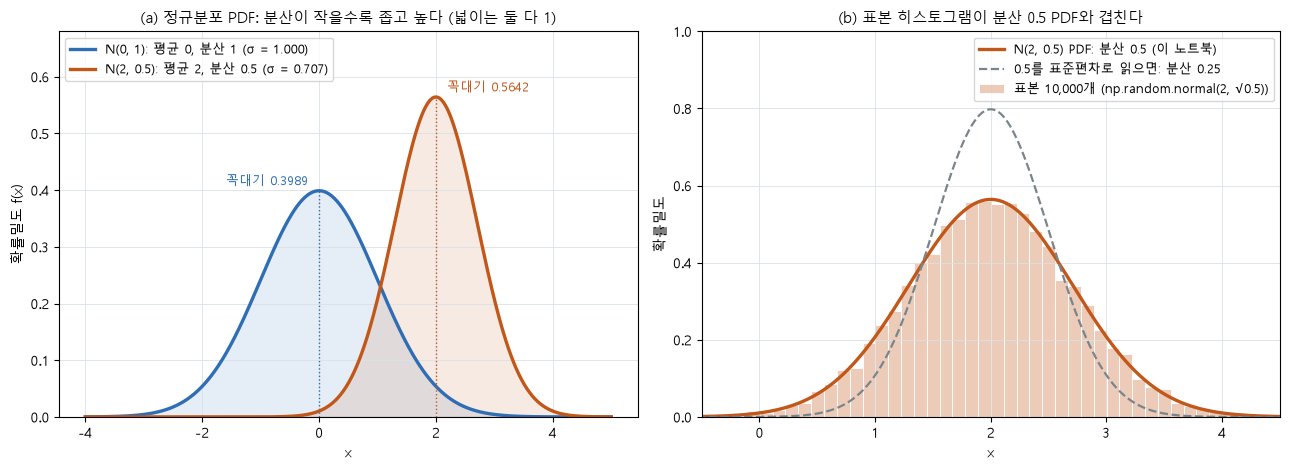

In [3]:
x = np.linspace(-4, 5, 600)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.8))

# (a) 두 PDF를 한 그림에
for mu, var, color in [(0, 1, BLUE), (2, 0.5, ORANGE)]:
    y = normal_pdf(x, mu, var)
    peak = normal_pdf(mu, mu, var)
    ax1.plot(x, y, color=color, lw=2.4, label=f"N({mu}, {var}): 평균 {mu}, 분산 {var} (σ = {np.sqrt(var):.3f})")
    ax1.fill_between(x, y, color=color, alpha=0.12)
    ax1.vlines(mu, 0, peak, color=color, lw=1, ls=":")
    left = mu == 0                                    # 파란 곡선은 왼쪽에 글자 (주황 곡선과 겹치지 않게)
    ax1.annotate(f"꼭대기 {peak:.4f}", (mu, peak), xytext=(-8 if left else 8, 4), textcoords="offset points",
                 fontsize=9.5, color=color, ha="right" if left else "left")
ax1.set_ylim(0, 0.68)
ax1.set_xlabel("x")
ax1.set_ylabel("확률밀도 f(x)")
ax1.set_title("(a) 정규분포 PDF: 분산이 작을수록 좁고 높다 (넓이는 둘 다 1)", fontsize=11)
ax1.legend(fontsize=9, loc="upper left")
ax1.grid(True, color="#D9E2E6", lw=0.6)

# (b) 표본 히스토그램(seaborn)과 PDF 비교 + 표기를 잘못 읽었을 때
sns.histplot(samples, stat="density", bins=50, color=ORANGE, alpha=0.3, edgecolor="white", ax=ax2,
             label=f"표본 10,000개 (np.random.normal(2, √0.5))")
ax2.plot(x, normal_pdf(x, 2, 0.5), color=ORANGE, lw=2.4, label="N(2, 0.5) PDF: 분산 0.5 (이 노트북)")
ax2.plot(x, normal_pdf(x, 2, 0.25), color=GRAY, lw=1.6, ls="--", label="0.5를 표준편차로 읽으면: 분산 0.25")
ax2.set_xlim(-0.5, 4.5)
ax2.set_ylim(0, 1.0)
ax2.set_xlabel("x")
ax2.set_ylabel("확률밀도")
ax2.set_title("(b) 표본 히스토그램이 분산 0.5 PDF와 겹친다", fontsize=11)
ax2.legend(fontsize=9, loc="upper right")
ax2.grid(True, color="#D9E2E6", lw=0.6)

fig.tight_layout()
saved(save_figure(fig, "normal_pdf.png"))
plt.show()

## 2. 베르누이분포의 확률질량 (PMF)

동전 던지기처럼 결과가 **1(성공) 또는 0(실패)** 둘뿐인 분포입니다. B(p)는 1이 나올 확률이 p입니다.

$$P(y \mid p) = p^{\,y}\,(1-p)^{\,1-y}, \qquad y \in \{0, 1\}$$

y = 1이면 p¹(1 − p)⁰ = p, y = 0이면 p⁰(1 − p)¹ = 1 − p. 한 줄로 두 경우를 쓰는 요령인데, 6장에서 이 모양이 그대로 BCE가 됩니다.

| 분포 | P(y = 0) | P(y = 1) | 평균 p | 분산 p(1 − p) |
|---|---|---|---|---|
| B(0.3) | 0.7 | 0.3 | 0.3 | 0.21 |
| B(0.7) | 0.3 | 0.7 | 0.7 | 0.21 |

연속인 정규분포는 "밀도(PDF)"라 값 하나하나가 확률이 아니었지만, 베르누이는 값이 띄엄띄엄(이산)이라 막대 높이가 곧 **확률(PMF)**이고 막대 높이의 합이 1입니다.

B(0.3):  P(0) = 0.7,  P(1) = 0.3,  합 = 1.0,  평균 = 0.3
B(0.7):  P(0) = 0.3,  P(1) = 0.7,  합 = 1.0,  평균 = 0.7
[통과] 베르누이 PMF 합 = 1, 평균 = p  


그림 저장: outputs/bernoulli_pmf.png


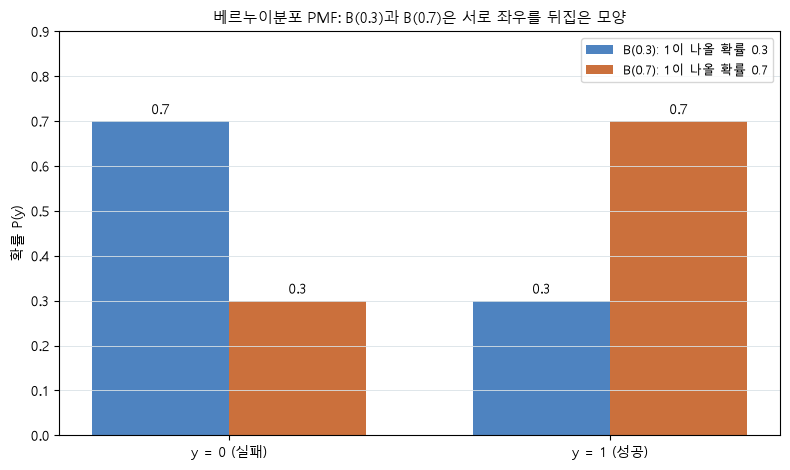

In [4]:
def bernoulli_pmf(y, p):
    """베르누이분포 B(p)의 확률질량 P(y) = p^y (1 − p)^(1 − y), y는 0 또는 1."""
    return p ** y * (1 - p) ** (1 - y)


ys = np.array([0, 1])
pmfs = {p: bernoulli_pmf(ys, p) for p in (0.3, 0.7)}
for p, pmf in pmfs.items():
    print(f"B({p}):  P(0) = {pmf[0]:.1f},  P(1) = {pmf[1]:.1f},  합 = {pmf.sum():.1f},  평균 = {np.sum(ys * pmf):.1f}")
check("베르누이 PMF 합 = 1, 평균 = p", all(np.isclose(pmf.sum(), 1) and np.isclose(np.sum(ys * pmf), p)
                                       for p, pmf in pmfs.items()))

fig, ax = plt.subplots(figsize=(8, 4.8))
width = 0.36
for shift, (p, color) in zip([-width / 2, width / 2], [(0.3, BLUE), (0.7, ORANGE)]):
    bars = ax.bar(ys + shift, pmfs[p], width=width, color=color, alpha=0.85, label=f"B({p}): 1이 나올 확률 {p}")
    ax.bar_label(bars, fmt="%.1f", padding=3, fontsize=10)
ax.set_xticks(ys, ["y = 0 (실패)", "y = 1 (성공)"])
ax.set_ylim(0, 0.9)
ax.set_ylabel("확률 P(y)")
ax.set_title("베르누이분포 PMF: B(0.3)과 B(0.7)은 서로 좌우를 뒤집은 모양", fontsize=11)
ax.legend(fontsize=9.5)
ax.grid(True, axis="y", color="#D9E2E6", lw=0.6)
fig.tight_layout()
saved(save_figure(fig, "bernoulli_pmf.png"))
plt.show()

## 3. softmax: 점수를 "합이 1인 확률"로

다중 분류 모델의 마지막 층은 클래스마다 점수 z(logit)를 냅니다. softmax는 이것을 확률로 바꿉니다.

$$\mathrm{softmax}(z)_k = \frac{e^{z_k}}{\sum_j e^{z_j}}$$

- e^z는 항상 양수 → 모든 출력이 0보다 큼
- 전체 합으로 나눔 → 출력의 합이 정확히 1
- 점수가 클수록 확률이 큼 (순서 유지)

### 손계산: z = [2.0, 1.0, 0.1]

```
e^2.0 = 7.3891,  e^1.0 = 2.7183,  e^0.1 = 1.1052      합 = 11.2125
softmax = [7.3891 / 11.2125,  2.7183 / 11.2125,  1.1052 / 11.2125] = [0.6590, 0.2424, 0.0986]
합 = 0.6590 + 0.2424 + 0.0986 = 1.0000
```

### 큰 점수에서 생기는 문제와 해결: 최댓값 빼기

컴퓨터의 e^z는 z가 약 709를 넘으면 너무 커서 무한대(inf)가 됩니다. 그러면 inf / inf = nan(숫자 아님)이 됩니다. 해결책은 **모든 점수에서 최댓값을 빼고** 계산하는 것입니다. 분자와 분모에 똑같이 e^(−max)가 곱해져 약분되므로 결과는 같고, 가장 큰 지수가 e⁰ = 1이 되어 넘치지 않습니다.

$$\frac{e^{z_k - m}}{\sum_j e^{z_j - m}} = \frac{e^{z_k} e^{-m}}{\left(\sum_j e^{z_j}\right) e^{-m}} = \mathrm{softmax}(z)_k$$

In [5]:
def softmax(z, axis=-1):
    """softmax. 최댓값을 먼저 빼서 e^z가 넘치지(overflow) 않게 한다. axis 방향으로 합이 1."""
    z = np.asarray(z, dtype=float)
    shifted = z - z.max(axis=axis, keepdims=True)      # 가장 큰 값이 0이 되도록
    e = np.exp(shifted)
    return e / e.sum(axis=axis, keepdims=True)


def softmax_naive(z):
    """비교용: 최댓값을 빼지 않는 그대로의 공식."""
    e = np.exp(np.asarray(z, dtype=float))
    return e / e.sum()


z = np.array([2.0, 1.0, 0.1])
p = softmax(z)
print("z =", z, "→ softmax =", p, " 합 =", p.sum())
check("softmax([2, 1, 0.1]) = 손계산 [0.6590, 0.2424, 0.0986]", np.allclose(np.round(p, 4), [0.6590, 0.2424, 0.0986]))

big = z + 1000                                          # [1002, 1001, 1000.1]
with np.errstate(over="ignore", invalid="ignore"):      # 일부러 넘치게 하는 비교라 경고는 끈다
    naive = softmax_naive(big)
print(f"\n점수에 1000을 더하면 {big}")
print("  그대로의 공식    :", naive, "  ← e^1002 = inf, inf / inf = nan")
print("  최댓값을 뺀 공식 :", softmax(big), "  ← 같은 수를 더해도 결과는 그대로")
check("큰 점수에서도 softmax가 안전 (같은 수를 더해도 결과 같음)",
      np.all(np.isnan(naive)) and np.allclose(softmax(big), p, rtol=0, atol=1e-12))

# 과제 기준: 출력 합과 1.0의 차이 ≤ 1e-6 — 무작위 점수 1,000세트(클래스 10개, 크기 최대 수백)로 확인
scores = np.random.randn(1000, 10) * 100
sums = softmax(scores, axis=1).sum(axis=1)
max_gap = np.max(np.abs(sums - 1.0))
check("softmax 출력 합과 1.0의 차이 ≤ 1e-6 (무작위 1,000세트)", max_gap <= 1e-6, f"최대 차이 {max_gap:.1e}")

z = [2.  1.  0.1] → softmax = [0.659  0.2424 0.0986]  합 = 1.0
[통과] softmax([2, 1, 0.1]) = 손계산 [0.6590, 0.2424, 0.0986]  

점수에 1000을 더하면 [1002.  1001.  1000.1]
  그대로의 공식    : [nan nan nan]   ← e^1002 = inf, inf / inf = nan
  최댓값을 뺀 공식 : [0.659  0.2424 0.0986]   ← 같은 수를 더해도 결과는 그대로
[통과] 큰 점수에서도 softmax가 안전 (같은 수를 더해도 결과 같음)  
[통과] softmax 출력 합과 1.0의 차이 ≤ 1e-6 (무작위 1,000세트)  최대 차이 2.2e-16


## 4. 최대우도추정 (MLE): "이 데이터가 나올 가능성이 가장 큰 파라미터"

동전을 4번 던져 **[1, 0, 1, 1]** (앞, 뒤, 앞, 앞)이 나왔습니다. 앞면 확률 p는 얼마라고 보는 게 가장 그럴듯할까요?

각 p에 대해 "이 결과가 나올 확률"을 계산합니다. 던지기는 서로 독립이라 곱합니다. 이것을 **가능도(likelihood)** L(p)라고 합니다.

$$L(p) = p \cdot (1-p) \cdot p \cdot p = p^3 (1-p)$$

| p | L(p) = p³(1 − p) |
|---|---|
| 0.5 | 0.0625 |
| 0.7 | 0.1029 |
| **0.75** | **0.1055** ← 가장 큼 |
| 0.9 | 0.0729 |

가장 큰 곳을 미분으로 찾습니다. 곱은 다루기 어려우니 **로그**를 씌워 합으로 바꿉니다 (log는 증가함수라 최댓값 위치가 그대로입니다).

$$\log L(p) = 3\log p + \log(1-p), \qquad \frac{d}{dp}\log L = \frac{3}{p} - \frac{1}{1-p} = 0 \;\Rightarrow\; p = \frac{3}{4}$$

답은 "4번 중 앞면 3번" = 0.75, 상식과 같습니다. 이렇게 **가능도를 최대로 만드는 파라미터를 고르는 것**이 MLE입니다.

학습에서는 "최대화" 대신 부호를 바꿔 **음의 로그 가능도(NLL)를 최소화**합니다. 이 NLL이 바로 손실 함수입니다. 아래에서 분포를 무엇으로 가정하느냐에 따라 NLL이 MSE가 되기도, Cross-Entropy가 되기도 하는 것을 봅니다.

In [6]:
toy = np.array([1, 0, 1, 1])
for p_try in [0.5, 0.7, 0.75, 0.9]:
    print(f"p = {p_try:<5}  L(p) = {np.prod(bernoulli_pmf(toy, p_try)):.4f}")

p = 0.5    L(p) = 0.0625
p = 0.7    L(p) = 0.1029
p = 0.75   L(p) = 0.1055
p = 0.9    L(p) = 0.0729


## 5. MSE 최소화 = 정규분포를 가정한 MLE

### 가정

회귀 모델이 예측 ŷᵢ를 내놓고, 실제 값 yᵢ는 **예측 주변에 정규분포로 흩어진다**고 가정합니다: yᵢ ~ N(ŷᵢ, σ²). (오차 yᵢ − ŷᵢ 가 평균 0, 분산 σ²인 정규분포)

### 유도

데이터 n개가 서로 독립이면 가능도는 PDF의 곱입니다.

$$L = \prod_{i=1}^{n} \frac{1}{\sqrt{2\pi\sigma^2}} \exp\!\left(-\frac{(y_i - \hat{y}_i)^2}{2\sigma^2}\right)$$

로그를 씌우면 곱이 합으로, exp가 사라집니다.

$$\log L = -\frac{n}{2}\log(2\pi\sigma^2) - \frac{1}{2\sigma^2}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2$$

부호를 바꾼 NLL:

$$\mathrm{NLL} = \underbrace{\frac{n}{2}\log(2\pi\sigma^2)}_{\hat{y}\text{와 무관한 상수}} + \underbrace{\frac{n}{2\sigma^2}}_{\text{양수 배}} \cdot \underbrace{\frac{1}{n}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2}_{\mathrm{MSE}}$$

NLL = (상수) + (양수) × MSE 이므로, **ŷ를 바꿔 가며 NLL을 최소화하는 것과 MSE를 최소화하는 것은 같은 답**을 줍니다. σ²가 얼마든 (양수 배율만 달라질 뿐) 최솟값 위치는 그대로라서, MSE 공식에는 σ가 보이지 않습니다.

### 숫자로 확인

N(2, 0.5)에서 뽑은 데이터 100개를 가장 단순한 모델 "ŷ = μ (모든 데이터를 상수 하나로 예측)"로 설명해 봅니다. μ 후보를 0.001 간격으로 바꿔 가며 NLL과 MSE를 계산하면, 둘 다 **표본 평균**에서 가장 작아야 합니다 (손으로도: d/dμ Σ(yᵢ − μ)² = −2Σ(yᵢ − μ) = 0 → μ = 평균).

In [7]:
n = 100
var = 0.5                                                # 가정한 분산 σ²
data = np.random.normal(2, np.sqrt(var), n)              # N(2, 0.5)에서 100개
mu_grid = np.round(np.linspace(0.5, 3.5, 3001), 3)       # μ 후보 (0.001 간격)

resid = data[None, :] - mu_grid[:, None]                 # (3001, 100): 후보마다 오차 yᵢ − μ
mse = np.mean(resid ** 2, axis=1)                                            # MSE
nll = -np.sum(np.log(normal_pdf(data[None, :], mu_grid[:, None], var)), axis=1)  # NLL: PDF 곱의 −log

# 유도한 식 NLL = n/2·log(2πσ²) + n/(2σ²)·MSE 이 숫자로도 맞는지
formula = n / 2 * np.log(2 * np.pi * var) + n / (2 * var) * mse
check("NLL = n/2·log(2πσ²) + n/(2σ²)·MSE (모든 μ 후보)", np.allclose(nll, formula, rtol=0, atol=1e-9),
      f"최대 차이 {np.max(np.abs(nll - formula)):.1e}")

mu_nll, mu_mse = mu_grid[np.argmin(nll)], mu_grid[np.argmin(mse)]
print(f"NLL이 가장 작은 μ = {mu_nll:.3f},  MSE가 가장 작은 μ = {mu_mse:.3f},  표본 평균 = {data.mean():.4f}")
check("NLL 최소 위치 = MSE 최소 위치 = 표본 평균", mu_nll == mu_mse and abs(mu_nll - data.mean()) <= 0.0005)

# σ²를 다르게 가정해도 최소 위치는 같다
nll_var2 = -np.sum(np.log(normal_pdf(data[None, :], mu_grid[:, None], 2.0)), axis=1)
print(f"σ² = 2.0으로 가정해도 NLL 최소 μ = {mu_grid[np.argmin(nll_var2)]:.3f}  (σ²는 위치에 영향 없음)")

[통과] NLL = n/2·log(2πσ²) + n/(2σ²)·MSE (모든 μ 후보)  최대 차이 1.7e-13
NLL이 가장 작은 μ = 1.929,  MSE가 가장 작은 μ = 1.929,  표본 평균 = 1.9287
[통과] NLL 최소 위치 = MSE 최소 위치 = 표본 평균  
σ² = 2.0으로 가정해도 NLL 최소 μ = 1.929  (σ²는 위치에 영향 없음)


## 6. Cross-Entropy 최소화 = 베르누이/카테고리 분포를 가정한 MLE

### 6-1. 이진 분류: 베르누이분포 → BCE

정답 yᵢ ∈ {0, 1}이 **모델이 낸 확률 ŷᵢ를 가진 베르누이분포**에서 나왔다고 가정합니다: yᵢ ~ B(ŷᵢ). 2장의 PMF를 그대로 곱합니다.

$$L = \prod_{i=1}^{n} \hat{y}_i^{\,y_i}(1-\hat{y}_i)^{1-y_i}
\quad\Rightarrow\quad
\mathrm{NLL} = -\sum_{i=1}^{n}\Big[\,y_i \log \hat{y}_i + (1-y_i)\log(1-\hat{y}_i)\,\Big]$$

괄호 안이 Step 5에서 쓴 **이진 교차 엔트로피(BCE)** 그 자체입니다. NLL / n = BCE 평균이므로, **BCE 최소화 = 베르누이 가정의 MLE**입니다. 지수였던 yᵢ, 1 − yᵢ가 로그를 씌우면 앞으로 내려와 "정답 쪽 확률의 로그만 고르는" 역할을 합니다.

숫자로 확인: B(0.7)에서 동전 100번을 던지고, 모든 던지기를 같은 확률 p로 설명할 때 (4장의 확장) NLL / n과 BCE가 같은지, 최소 위치가 앞면 비율 p̂인지 봅니다.

In [8]:
flips = (np.random.rand(100) < 0.7).astype(float)         # B(0.7)에서 100번 (1 = 앞면)
p_hat = flips.mean()
p_grid = np.round(np.linspace(0.01, 0.99, 981), 3)       # p 후보 (0.001 간격)

nll_b = -np.sum(np.log(bernoulli_pmf(flips[None, :], p_grid[:, None])), axis=1)          # PMF 곱의 −log
bce_b = -np.mean(flips[None, :] * np.log(p_grid[:, None])
                 + (1 - flips[None, :]) * np.log(1 - p_grid[:, None]), axis=1)          # BCE 평균

check("베르누이 NLL / n = BCE (모든 p 후보)", np.allclose(nll_b / len(flips), bce_b, rtol=0, atol=1e-12))
p_best = p_grid[np.argmin(bce_b)]
print(f"앞면 {int(flips.sum())}번 / 100번 → p̂ = {p_hat:.2f},  BCE가 가장 작은 p = {p_best:.3f}")
check("BCE 최소 위치 = 앞면 비율 p̂", abs(p_best - p_hat) <= 0.0005)

[통과] 베르누이 NLL / n = BCE (모든 p 후보)  
앞면 75번 / 100번 → p̂ = 0.75,  BCE가 가장 작은 p = 0.750
[통과] BCE 최소 위치 = 앞면 비율 p̂  


그림 저장: outputs/mle_loss.png


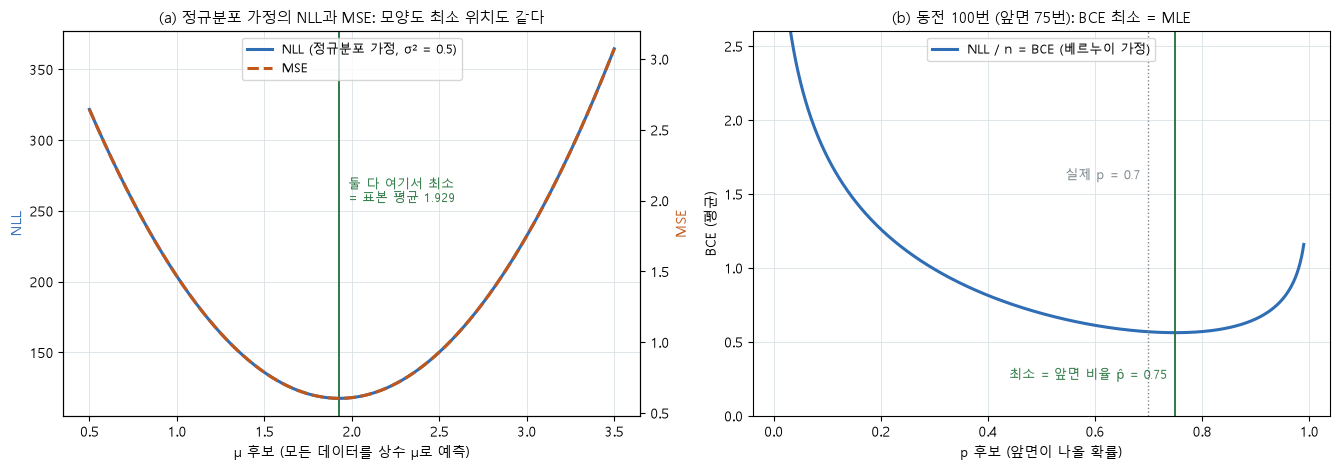

In [9]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.5, 4.8))

# (a) 정규 가정: NLL(왼쪽 축)과 MSE(오른쪽 축)
ax1.plot(mu_grid, nll, color=BLUE, lw=2.2, label="NLL (정규분포 가정, σ² = 0.5)")
ax1.set_xlabel("μ 후보 (모든 데이터를 상수 μ로 예측)")
ax1.set_ylabel("NLL", color=BLUE)
ax1b = ax1.twinx()
ax1b.plot(mu_grid, mse, color=ORANGE, lw=2.2, ls="--", label="MSE")
ax1b.set_ylabel("MSE", color=ORANGE)
ax1.axvline(data.mean(), color=GREEN, lw=1.4)
ax1.text(data.mean() + 0.05, 0.62, f"둘 다 여기서 최소\n= 표본 평균 {data.mean():.3f}",
         transform=ax1.get_xaxis_transform(),            # x는 μ 값, y는 그림 높이의 비율
         color=GREEN, fontsize=9.5, va="top")
lines = ax1.get_legend_handles_labels()[0] + ax1b.get_legend_handles_labels()[0]
ax1.legend(lines, [l.get_label() for l in lines], fontsize=9, loc="upper center")
ax1.set_title("(a) 정규분포 가정의 NLL과 MSE: 모양도 최소 위치도 같다", fontsize=11)
ax1.grid(True, color="#D9E2E6", lw=0.6)

# (b) 베르누이 가정: NLL / n = BCE
ax2.plot(p_grid, bce_b, color=BLUE, lw=2.2, label="NLL / n = BCE (베르누이 가정)")
ax2.axvline(p_hat, color=GREEN, lw=1.4)
ax2.axvline(0.7, color=GRAY, lw=1, ls=":")
ax2.text(p_hat - 0.015, 0.25, f"최소 = 앞면 비율 p̂ = {p_hat:.2f}", color=GREEN, fontsize=9.5, ha="right")
ax2.text(0.7 - 0.015, 1.6, "실제 p = 0.7", color=GRAY, fontsize=9, ha="right")
ax2.set_ylim(0, 2.6)
ax2.set_xlabel("p 후보 (앞면이 나올 확률)")
ax2.set_ylabel("BCE (평균)")
ax2.set_title(f"(b) 동전 100번 (앞면 {int(flips.sum())}번): BCE 최소 = MLE", fontsize=11)
ax2.legend(fontsize=9, loc="upper center")
ax2.grid(True, color="#D9E2E6", lw=0.6)

fig.tight_layout()
saved(save_figure(fig, "mle_loss.png"))
plt.show()

### 6-2. 다중 분류: 카테고리분포 → Cross-Entropy

클래스가 K개면 정답을 원-핫 벡터 y = (y₁, …, y_K)로 씁니다 (정답 칸만 1). 모델이 softmax로 낸 확률 p = (p₁, …, p_K)를 가진 **카테고리분포**를 가정하면, 한 데이터의 확률은

$$P(y \mid p) = \prod_{k=1}^{K} p_k^{\,y_k} \quad (\text{정답 칸 } c \text{의 } p_c \text{만 남음})$$

데이터 n개의 NLL은

$$\mathrm{NLL} = -\sum_{i=1}^{n}\sum_{k=1}^{K} y_{ik}\log p_{ik}$$

이것이 **Cross-Entropy**입니다. K = 2이면 6-1의 BCE와 같은 식이 됩니다 (p₂ = 1 − p₁).

숫자로 확인: 실제 확률 [0.2, 0.5, 0.3]인 3클래스에서 200개를 뽑고, 모든 데이터를 같은 확률 q로 설명할 때 Cross-Entropy가 **클래스별 비율(빈도)**에서 가장 작은지, 무작위 확률 벡터 1,000개와 비교합니다.

In [10]:
labels = np.random.choice(3, size=200, p=[0.2, 0.5, 0.3])   # 클래스 0, 1, 2
Y = np.eye(3)[labels]                                          # 원-핫 (200, 3)
freq = Y.mean(axis=0)                                          # 클래스별 비율 = MLE 후보


def cross_entropy(Y, q):
    """평균 Cross-Entropy: −(1/n) Σᵢ Σₖ yᵢₖ log qₖ  (q는 모든 데이터에 같은 확률 벡터)."""
    return -np.mean(np.sum(Y * np.log(q), axis=1))


ce_freq = cross_entropy(Y, freq)
candidates = np.random.dirichlet(np.ones(3), size=1000)       # 합이 1인 무작위 확률 벡터 1,000개
ce_cand = np.array([cross_entropy(Y, q) for q in candidates])
print(f"클래스별 비율 {freq} 의 Cross-Entropy = {ce_freq:.4f}")
print(f"무작위 확률 벡터 1,000개의 Cross-Entropy: 최소 {ce_cand.min():.4f}, 평균 {ce_cand.mean():.4f}")
check("Cross-Entropy 최소 = 클래스별 비율 (무작위 1,000개보다 작음)", ce_freq < ce_cand.min())

클래스별 비율 [0.215 0.51  0.275] 의 Cross-Entropy = 1.0289
무작위 확률 벡터 1,000개의 Cross-Entropy: 최소 1.0294, 평균 1.5229
[통과] Cross-Entropy 최소 = 클래스별 비율 (무작위 1,000개보다 작음)  


### 6-3. Step 5와 연결: softmax + Cross-Entropy의 기울기 = p − y

정답 클래스가 c이면 L = −log p_c = −z_c + log Σⱼ e^{z_j} 이므로

$$\frac{\partial L}{\partial z_k} = -[k = c] + \frac{e^{z_k}}{\sum_j e^{z_j}} = p_k - y_k$$

Step 5에서 sigmoid + BCE의 기울기가 **ŷ − y**(예측 − 정답)였던 것과 같은 모양입니다. 두 경우 모두 "확률분포를 가정하고 MLE로 만든 손실"이라 출력 함수(sigmoid, softmax)의 미분과 깔끔하게 약분되기 때문입니다. Step 4의 수치 미분으로 확인합니다.

In [11]:
z = np.array([2.0, 1.0, 0.1])
y_onehot = np.array([0.0, 1.0, 0.0])                     # 정답은 두 번째 클래스


def ce_of_logits(z_):
    """점수 z → softmax → 정답 클래스의 −log 확률."""
    return -np.sum(y_onehot * np.log(softmax(z_)))


g_numeric = numerical_gradient(ce_of_logits, z)          # 공식 없이 잰 기울기
g_formula = softmax(z) - y_onehot                        # p − y
print("수치 미분:", g_numeric)
print("p − y    :", g_formula)
check("softmax + Cross-Entropy 기울기 = p − y", np.allclose(g_numeric, g_formula, rtol=0, atol=1e-8),
      f"최대 차이 {np.max(np.abs(g_numeric - g_formula)):.1e}")

수치 미분: [ 0.659  -0.7576  0.0986]
p − y    : [ 0.659  -0.7576  0.0986]
[통과] softmax + Cross-Entropy 기울기 = p − y  최대 차이 6.9e-12


## 7. 정리

| 가정한 분포 (정답이 어떻게 생겼나) | 그 분포의 NLL = 손실 함수 | 출력 함수 | 쓰는 곳 | 출력층 기울기 |
|---|---|---|---|---|
| 정규분포 y ~ N(ŷ, σ²) | **MSE** (상수·배율 차이만) | 없음 (그대로) | 회귀 (숫자 예측) | ∝ ŷ − y |
| 베르누이분포 y ~ B(ŷ) | **BCE** | sigmoid | 이진 분류 | ŷ − y (Step 5) |
| 카테고리분포 y ~ Cat(p) | **Cross-Entropy** | softmax | 다중 분류 | p − y |

- 손실 함수는 "정답이 이런 분포에서 나왔다"는 가정 아래 **데이터가 나올 가능성(가능도)을 최대로 만드는 것**과 같습니다.
- 그래서 문제에 맞는 분포를 고르면 손실 함수가 정해집니다: 연속값이면 정규 → MSE, 0/1이면 베르누이 → BCE, 여러 클래스면 카테고리 → CE.
- 정규분포 표기 N(2, 0.5)는 이 노트북에서 **분산 0.5**로 읽었습니다 (NumPy에는 표준편차 √0.5를 넘김).

In [12]:
print(f"전체: {sum(results)}/{len(results)} 통과")

전체: 12/12 통과
